# 7. Мета-анализ эффектов на долю завершивших

Это исследовательский вывод, а не решение по конкретному тесту. Вопрос: каких эффектов вообще ждать от изменений
задания в этой платформе и какой MDE реалистично закладывать в будущие тесты.

Модель - случайные эффекты по DerSimonian-Laird на 21 эксперименте (без 263057). Эффект - разница долей E - C,
дисперсия - как в интервале Вальда. Оговорки:
- условия в экспериментах разные, общая оценка - это средний эффект «какого-то изменения задания», а не одного условия;
- треть учеников участвовала в нескольких экспериментах, оценки не независимы, и обычный интервал мета-анализа может
  быть слишком узким. Поэтому дополнительно считаю интервал бутстрепом по ученикам: пересэмплирую учеников целиком,
  со всеми их экспериментами;
- разница в п.п. зависит от базовой доли: при контроле 98% расти почти некуда. Альтернатива - мета-анализ на шкале
  логарифма отношения шансов.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config, db, effects, plots, stats

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
con = db.connect()

In [2]:
wide = effects.completion_wide(con)
main = effects.effects(wide[wide["sample"] == "all"], np.random.default_rng(config.SEED))
m = main[main.experiment_id != effects.EXCLUDED].reset_index(drop=True)
m["var"] = m.rate_e * (1 - m.rate_e) / m.n_e + m.rate_c * (1 - m.rate_c) / m.n_c
res = stats.dl_meta(m["diff"], m["var"])
w = 1 / m["var"]
print("общая оценка, п.п.:", round(100 * res["estimate"], 2),
      " интервал 95%:", round(100 * res["ci"][0], 2), "...", round(100 * res["ci"][1], 2))
print("tau^2:", round(res["tau2"], 6), " I^2:", round(res["i2"], 3), " Q:", round(res["q"], 2),
      "при", len(m) - 1, "степенях свободы, p =", round(res["q_p"], 3))
print("интервал предсказания, п.п.:", round(100 * res["pi"][0], 2), "...", round(100 * res["pi"][1], 2))
print("модель с фиксированным эффектом, п.п.:", round(100 * np.sum(w * m["diff"]) / w.sum(), 2))

общая оценка, п.п.: -1.33  интервал 95%: -2.33 ... -0.33
tau^2: 0.0  I^2: 0.0  Q: 14.29 при 20 степенях свободы, p = 0.816
интервал предсказания, п.п.: -2.4 ... -0.26
модель с фиксированным эффектом, п.п.: -1.33


In [3]:
loo = [stats.dl_meta(m["diff"].drop(i), m["var"].drop(i))["estimate"] for i in m.index]
print("без одного эксперимента оценка от", round(100 * min(loo), 2), "до", round(100 * max(loo), 2), "п.п.")
print("самый влиятельный:", m.experiment_id[int(np.argmax(np.abs(np.array(loo) - res["estimate"])))])

без одного эксперимента оценка от -1.53 до -1.07 п.п.
самый влиятельный: 237447


## Интервал с учётом общих учеников

Бутстреп по ученикам: в каждом повторе беру 8 205 учеников с возвращением, каждый приносит все свои строки. Для
каждого эксперимента пересчитываю разницу долей и её дисперсию, потом общую оценку DerSimonian-Laird.

In [4]:
rows = db.run(con, "groups.sql", "completion_rows")
rows = rows[rows.experiment_id != effects.EXCLUDED]
user_idx = pd.factorize(rows.user_id)[0]
exp_ids = m.experiment_id.values
cell = rows.experiment_id.map({e: i for i, e in enumerate(exp_ids)}).values * 2 + (rows.grp == "E").values
done = rows.complete.values.astype(float)
n_users, n_cells = user_idx.max() + 1, 2 * len(exp_ids)

rng = np.random.default_rng(config.SEED)
boot = []
for _ in range(2000):
    w_user = np.bincount(rng.integers(0, n_users, n_users), minlength=n_users)
    w_row = w_user[user_idx]
    n = np.bincount(cell, weights=w_row, minlength=n_cells).reshape(-1, 2)
    x = np.bincount(cell, weights=w_row * done, minlength=n_cells).reshape(-1, 2)
    p = x / n
    var = p[:, 1] * (1 - p[:, 1]) / n[:, 1] + p[:, 0] * (1 - p[:, 0]) / n[:, 0]
    boot.append(stats.dl_meta(p[:, 1] - p[:, 0], var)["estimate"])
boot = np.array(boot)
lo, hi = np.quantile(boot, [0.025, 0.975])
print("бутстреп по ученикам, интервал 95%, п.п.:", round(100 * lo, 2), "...", round(100 * hi, 2))
print("отношение ширины к обычному интервалу:", round((hi - lo) / (res["ci"][1] - res["ci"][0]), 2))

бутстреп по ученикам, интервал 95%, п.п.: -2.42 ... -0.24
отношение ширины к обычному интервалу: 1.09


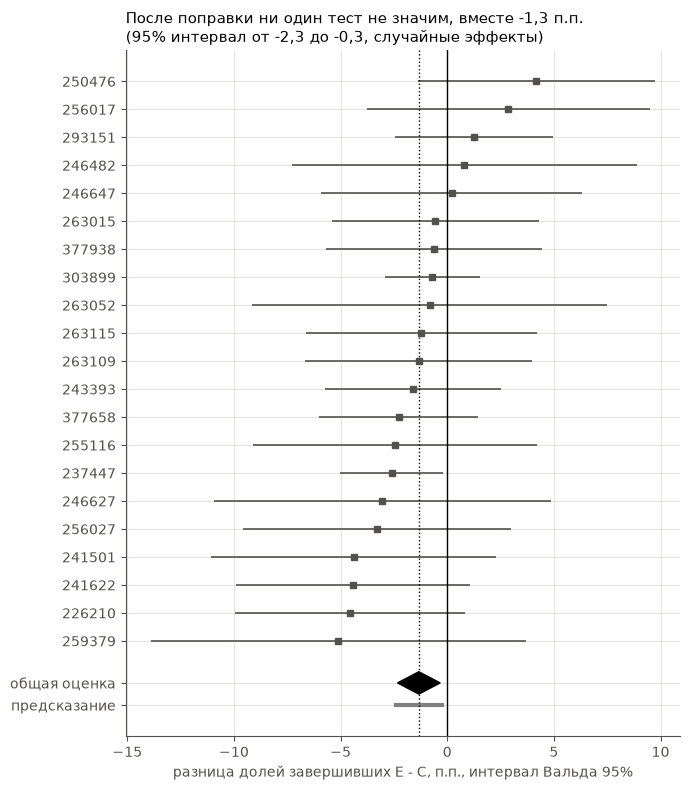

In [5]:
d = m.sort_values("diff").reset_index(drop=True)
plots.setup()
fig, ax = plt.subplots(figsize=(7, 8))
ax.errorbar(100 * d["diff"], d.index, xerr=[100 * (d["diff"] - d.wald_lo), 100 * (d.wald_hi - d["diff"])],
            fmt="s", color=plots.INK, markersize=4, elinewidth=1.2)
y = -1.5
est, (clo, chi), (plo, phi) = res["estimate"], res["ci"], res["pi"]
ax.fill([100 * clo, 100 * est, 100 * chi, 100 * est], [y, y + 0.4, y, y - 0.4], color="black")
ax.plot([100 * plo, 100 * phi], [y - 0.8, y - 0.8], color="grey", linewidth=3)
ax.axvline(0, color="black", linewidth=1)
ax.axvline(100 * est, color="black", linestyle=":", linewidth=1)
ax.set_yticks(list(d.index) + [y, y - 0.8], list(d.experiment_id.astype(str)) + ["общая оценка", "предсказание"])
ax.set_xlabel("разница долей завершивших E - C, п.п., интервал Вальда 95%")
pp = lambda v: f"{100 * v:.1f}".replace(".", ",")
ax.set_title(f"После поправки ни один тест не значим, вместе {pp(est)} п.п.\n"
             f"(95% интервал от {pp(clo)} до {pp(chi)}, случайные эффекты)")
plt.tight_layout()
# эта же картинка в README
plots.save(fig, "meta_forest.png")

## Какой MDE реалистичен

Если истинные эффекты изменений в этой платформе порядка одного-двух п.п., тест надо планировать на такой эффект.
Считаю размер групп при медианной доле завершивших в контроле.

In [6]:
base = m.rate_c.median()
print("медианная доля завершивших в контроле:", round(base, 3))
plan = pd.DataFrame({"эффект, п.п.": [1, 1.3, 2, 3]})
for sign, name in [(1, "рост"), (-1, "падение")]:
    plan[f"учеников в группе ({name})"] = [np.ceil(stats.n_two_prop(base, sign * e / 100)) for e in plan["эффект, п.п."]]
plan

медианная доля завершивших в контроле: 0.863


,"эффект, п.п.",учеников в группе (рост),учеников в группе (падение)
0,1.0,18001.0,19140.0
1,1.3,10548.0,11425.0
2,2.0,4354.0,4924.0
3,3.0,1869.0,2249.0


## Итог

- Общая оценка -1,3 п.п., интервал от -2,3 до -0,3. В среднем изменение задания в этих экспериментах немного снижало
  долю завершивших. Это согласуется с этапом 3: в 16 из 21 эксперимента точечная оценка ниже нуля.
- Неоднородности не видно: tau^2 = 0, I^2 = 0, Q = 14,3 при 20 степенях свободы (p = 0,82). Разброс эффектов между
  экспериментами не больше, чем дал бы шум выборки. Но на 21 маленьком тесте мощность заметить неоднородность низкая,
  так что «эффекты одинаковые» из этого не следует.
- Устойчивость. Без любого одного эксперимента оценка от -1,5 до -1,1 п.п., сильнее всех влияет 237447. Бутстреп по
  ученикам с учётом общих учеников даёт интервал от -2,4 до -0,2, всего в 1,09 раза шире обычного. Зависимость между
  экспериментами вывод не меняет.
- Что это значит для будущих тестов. Реалистичный масштаб эффекта изменения - единицы п.п., скорее около 1-2, а не 3 и
  больше. При медианной доле завершивших 86% для 2 п.п. нужно около 4 400 учеников в группе, для 1,3 п.п. - около
  10 500. Типичный эксперимент здесь - около 260 учеников в группе с MDE 7,6 п.п., он мог заметить только эффект,
  в несколько раз больше реалистичного.
- Чего этот вывод не даёт: решения по конкретному условию. Общая оценка - среднее по разным условиям, и
  отрицательное среднее не значит, что каждое из них вредно.